<h2>
  Vignette 07: Fine Alignment &amp; NeuN+ Profiling<br>
  <span style="font-size: 12px; font-weight: normal; display: block">
    <i>"Everything, everything, everything in its right place" - Radiohead</i><br>
  </span>
</h2>

The ultimate goal of spatial genomics pipelines is to easily use all layers of data simultaneously.

As an example, for the Visium dataset we presented earlier, we have DAPI and NeuN immunofluorescent
images of the tissue that was captured for transcriptional analysis. It would be ideal to map these
immunofluorescent cells directly to transcript level data, but this is technically challenging.

While SpaceRanger does a decent job of coarse registration of the images with the transcript data, when 
both are viewed at high magnification it becomes clear that they are not perfectly aligned, and the 
IF images are offset by a few microns.  This offset isn't consistent, because when the tissue is 
transfered to the capture grid there is a small amount of stretching/ movement.  While this displacement 
may only be a few microns, it means that a cell identified in IF may only partly overlap the transcript data, 
or even partly overlap another adjacent cell.

In this vignette we will show how we can leverage the spatial alignment tools in platpy to fine-algign the
IF and spot-data representations of the Visium sample, allowing for a more precise cell segmentation
than possible with spot-level data alone. 

In this vignette, we will:
1. Demonstrate the displacement present in a SpaceRanger aligned dataset
2. Generate a fine-alignment correction and apply it to the Visium 'omic layer
3. Use the immunofluorescent channels to segment the fine-aligned transcript data
4. Build a single-cell AnnData and produce a spatially-resolved UMAP

In [11]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm as notebook_tqdm
from platpy.io_utils import load_sample
from platpy.plot_utils import plot_image_grid
from platpy.dataport import DataPort

# Load in the Visium sample data.
sample_dir = Path.home() / 'platpy_data' / 'VisiumSample'
sample = load_sample(sample_dir, verbose=True)

# This Visium image was captured upside down; flip for anatomical orientation throughout
sample.view_defaults['flip_y'] = True


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
  - Images available: 'dapi' (16g), 'detected' (24c), 'hires' (24c), 'lowres' (24c), 'neun' (16g)
  - Image channels loaded: dapi, detected, hires, lowres, neun
  - Omic channels loaded: spots
  - Cell channels loaded: 
  - ROIs loaded: 


### Step 1: The problem: SpaceRanger alignment is good, but not perfect

Both DAPI and total transcript counts are proxies for **cell density**. In a perfectly aligned
dataset they should look almost identical at any zoom level. Below we render both for the same 
cortical region and zoom in tight enough to see individual nuclei. Spot centres should sit on 
top of bright DAPI nuclei; if they're offset it will show in the image below.


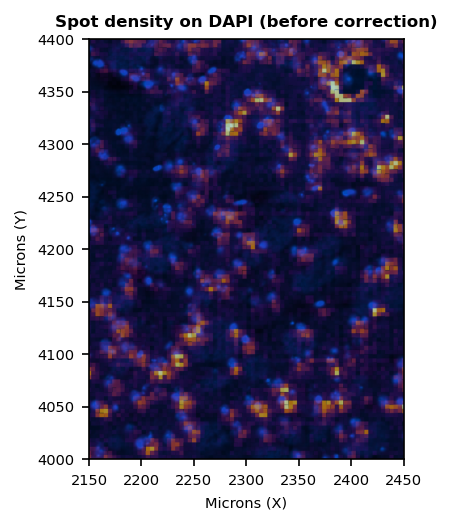

In [12]:
# Tight zoom: DAPI + spot density overlay; individual nuclei are visible at this scale

vp_tight = sample.viewport(center_um=(2300, 4200), fov_um=(300, 400))
vp_tight.add_layer(sample.images['dapi']).adjust_layer(
    tint='xkcd:bright blue', gamma=1.2, percentile_clip=(5, 99), blend_mode='lighten')
vp_tight.add_layer(sample.omics['spots']).adjust_layer(
    gene_name='total_counts', cmap_name='inferno', alpha=0.7, alpha_gamma=0.3)

plot_image_grid(vp_tight.render(),
    titles=['Spot density on DAPI (before correction)'],
    width=3, font_size='small');


### Step 2: Compute a fine-alignment correction for the spot-level data

In a well aligned sample, the DAPI and transcript count data should overlap tightly.  While
some cells may have higher or lower expression than their neighbors, spots expressing significant
transcript levels should overlap DAPI+ nuclei profiles and not sit over "empty space"

The compute_fine_alignment() function builds matching density and DAPI grids internally via the 
ViewPort pipeline, runs block-level phase cross-correlation across the tissue, fits a smooth 
displacement field, and stores the result in sample.metadata['fine_spatial'] for downstream use.

[fine align] Step 1: rendering spot density via ViewPort (1206 px at 4 µm/px) ...
[fine align] Step 2: rendering DAPI via same ViewPort ...
[fine align]   grid shape: (1651, 1206)  origin: (0.0, 0.0)
[fine align] Step 3: block matching  (block=80px, stride=10px) ...
[fine align]   12211 valid blocks before outlier filter
[fine align]   outlier filter: removed 249 of 12211 blocks  (dy median=1.55px, dx median=-1.15px)
[fine align]   11962 blocks after outlier filter
[fine align] Step 4: fitting displacement field (method='pixel') ...
[fine align] Done. max_displacement_um=13.30 µm. Stored in sample.metadata['fine_spatial'].


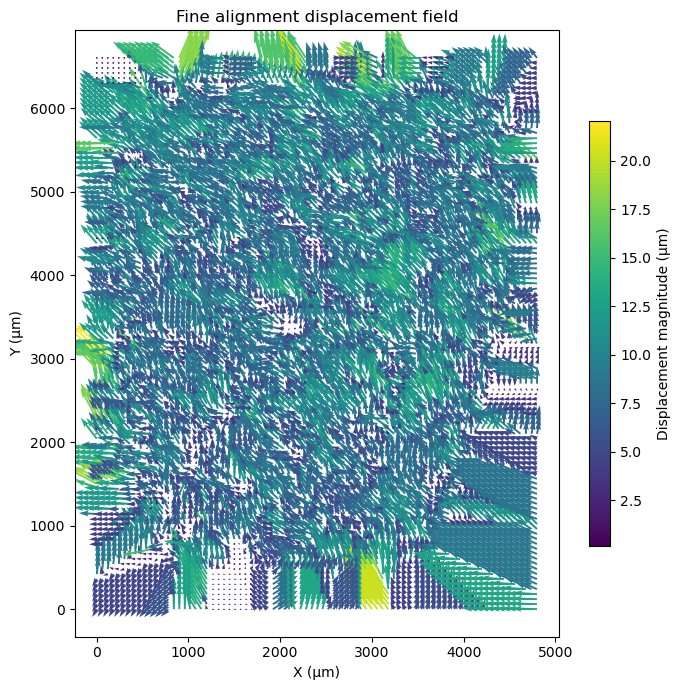

dy  -4.3 to 16.6 µm  (median 5.7 µm)
dx  -16.6 to 7.2 µm  (median -4.7 µm)


In [13]:
from platpy.align_utils import compute_fine_alignment, plot_displacement_field

# Compute displacement field and display the arrow map

#    Note: there are two methods for computing fine alignment; a pixel displacement field ('pixel', which
#    is an evenly spaced array of vectors that mark how much offset is present at each location), or 
#    a thin-plate spline ('tps', which is a set of control points that warp the image).  
#    The 'pixel' method produced slightly better results for this sample so that is used here.

fa = compute_fine_alignment(sample, sample.images['dapi'], method='pixel', resolution_um=4, stride_um=40)
plot_displacement_field(fa, figsize=(7, 7));

print(f'dy  {fa.field_dy_um.min():.1f} to {fa.field_dy_um.max():.1f} \u00b5m  (median {np.median(fa.field_dy_um):.1f} \u00b5m)')
print(f'dx  {fa.field_dx_um.min():.1f} to {fa.field_dx_um.max():.1f} \u00b5m  (median {np.median(fa.field_dx_um):.1f} \u00b5m)')


### Step 3: Validate fine alignment: Check spot centres before and after correction

Let's check our close-up view again, to see if the fine alignment fixes the displacement
of the spots relative to the DAPI image.  We'll show two views the first is axis-aligned
to the dapi image, the second is slightly rotated and upscaled.  The result: the Visium
spots appear more closely aligned to the DAPI image, and this adjustment survives
scaling and rotating the image.

Correction  median=7.5 µm  max=22.1 µm  max_field=13.3 µm  (2,170,414 spots)


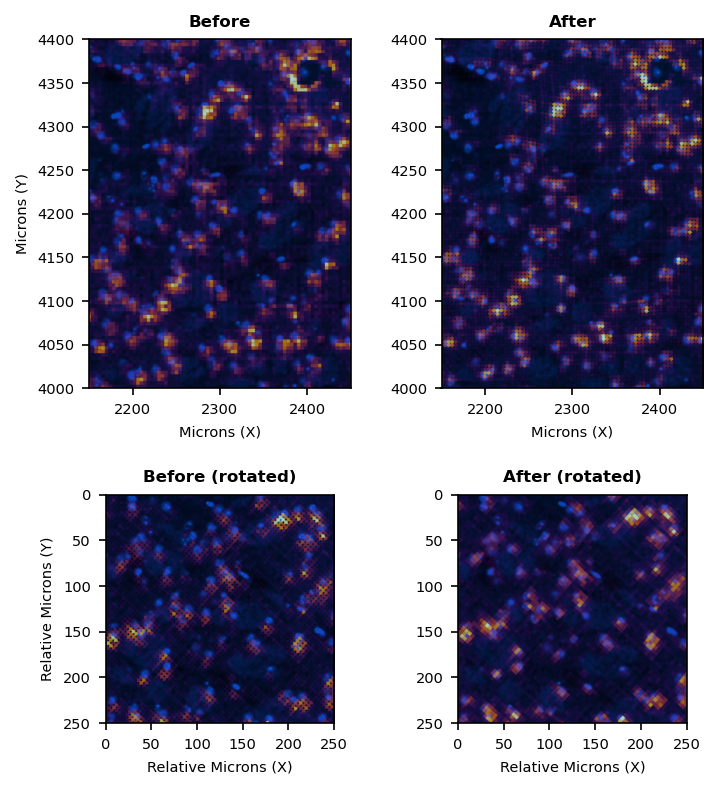

In [14]:
from platpy.align_utils import apply_fine_alignment

apply_fine_alignment(sample.omics['spots'], sample, in_place=True)

# Render all four views while toggling fine alignment
# Row 1: standard zoom  |  Row 2: rotated + tighter FOV (proves alignment holds under rotation)
def _make_vp(center, fov, rot=0):
    vp = sample.viewport(center_um=center, fov_um=fov, rotation_deg=rot)
    vp.add_layer(sample.images['dapi']).adjust_layer(
        tint='xkcd:bright blue', gamma=1.2, percentile_clip=(5, 99), blend_mode='lighten')
    vp.add_layer(sample.omics['spots']).adjust_layer(
        gene_name='total_counts', cmap_name='inferno', alpha=0.7, alpha_gamma=0.3)
    return vp

sample.omics['spots'].use_fine_alignment = False
render_before     = _make_vp((2300, 4200), (300, 400)).render()
render_before_rot = _make_vp((2300, 4200), (250, 250), rot=42).render()

sample.omics['spots'].use_fine_alignment = True
render_after     = _make_vp((2300, 4200), (300, 400)).render()
render_after_rot = _make_vp((2300, 4200), (250, 250), rot=42).render()

plot_image_grid(
    [render_before, render_after, render_before_rot, render_after_rot],
    titles=['Before', 'After', 'Before (rotated)', 'After (rotated)'],
    columns=2, width=5, font_size='small')

# Quantify the correction
coords_raw  = sample.omics['spots'].data.obsm['spatial']
coords_corr = sample.omics['spots'].data.obsm['spatial_fine']
mag_all = np.sqrt(((coords_corr - coords_raw)**2).sum(axis=1))
print(f'Correction  median={np.median(mag_all):.1f} \u00b5m  max={mag_all.max():.1f} \u00b5m  max_field={sample.omics["spots"].fine_alignment.max_displacement_um:.1f} \u00b5m  ({len(mag_all):,} spots)')

### Step 4: NeuN segmentation on the fine-aligned data

To segment Visium spots into cells, we are going to use the NeuN channel.  Not only does NeuN
focus on the primary cell type (Neurons), but it is a robust nuclear label that gives dramatically
cleaner segmentation in Cellpose than DAPI does.  NeuN labels **most** neurons, so we'll start by
picking them out and assigning those spots to cells, and we'll come back for the rest later.

Of note, we're using the same `DataPort.process()` pipeline as Vignette 03 to segment via Cellpose
(by passing the active model to the function). As before, neither the model or settings are built
in to platpy, so changing to StarDist or another function is straightforward.  

We've already applied the fine alignment in-place to `sample.omics['spots']` in Step 3, so when we
assign the spots to cells with `get_active_coords()` it automatically uses the corrected values
unless we ask it specifically not to.

pretrained model C:\Users\maynard\.cellpose\models\cpsam not found, using default model
channels deprecated in v4.0.1+. If data contain more than 3 channels, only the first 3 channels will be used


Segmented 784 NeuN+ nuclei
Estimated nucleus diameter: 7.7 px = 15.3 um (at 2 um/px)
  Spatial index: 1102 bins at 200 µm  |  2,170,414 spots
  Cells retained: 761  (from 784 boundaries, min_obs=5)
Cells x genes AnnData: 761 cells, 19,059 genes


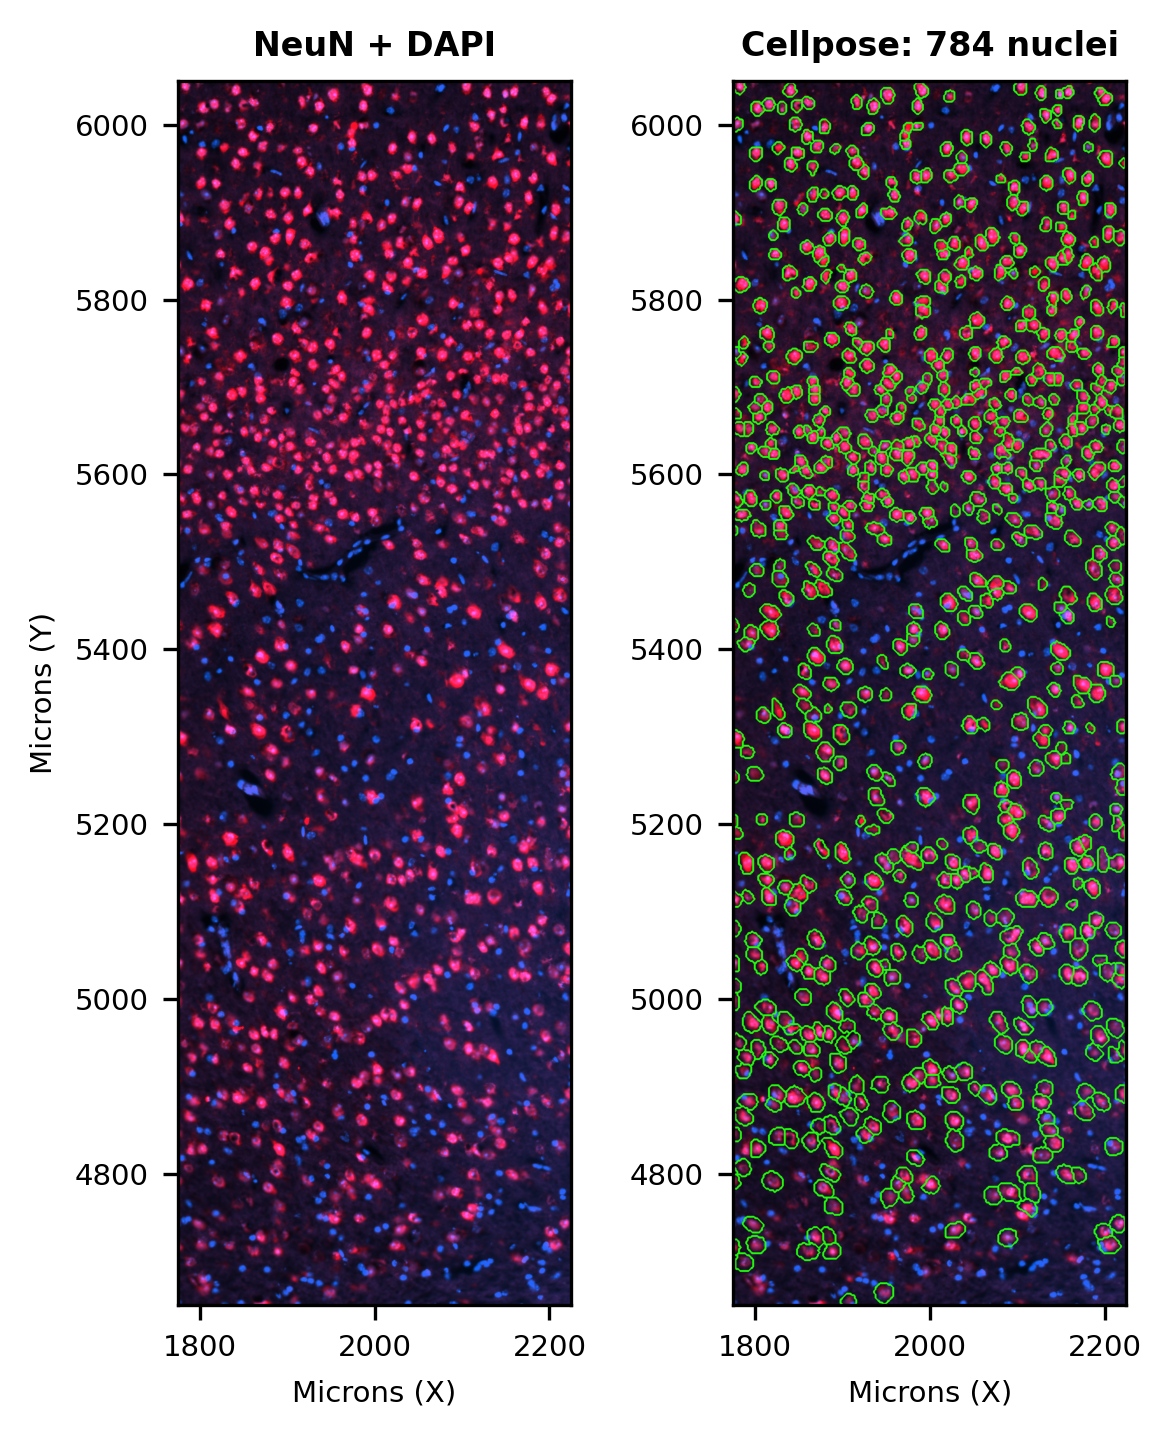

In [15]:
from cellpose import models
from platpy.cell_utils import make_cells_from_masks
import torch

# Set ViewPort / DataPort to a strip of the cortex for analysis
vp_ctx = sample.viewport(center_um=(2000, 5350), fov_um=(450, 1400))
vp_ctx.add_layer(sample.images['dapi']).adjust_layer(
    tint='xkcd:bright blue', gamma=1.2, percentile_clip=(5, 99), blend_mode='lighten')
vp_ctx.add_layer(sample.images['neun']).adjust_layer(
    tint='xkcd:bright red',  gamma=0.8, percentile_clip=(5, 99), blend_mode='lighten')
dp_ctx = DataPort.from_viewport(vp_ctx)

# Segment the NeuN+ nuclei with Cellpose for the selected region
model = models.CellposeModel(gpu=True, pretrained_model='nuclei')

results = dp_ctx.process(
    sample.images['neun'],
    fn=lambda arr: model.eval(arr, diameter=None, channels=[0, 0])[0],
    downsample_mpp=2.0
)
extent_ctx_um, masks = results[0]

# PyTorch MPS (Apple Silicon) holds inference-time tensors in a cache even after they're freed.
# empty_cache() returns that pool to the OS without unloading the model weights.
if torch.backends.mps.is_available():
    torch.mps.empty_cache()
elif torch.cuda.is_available():
    torch.cuda.empty_cache()

# Capture raw NeuN intensities at same resolution Ã¢â‚¬â€ used for non-neuronal QC in Step 5
_, neun_arr = dp_ctx.process(sample.images['neun'], fn=lambda arr: arr, downsample_mpp=2.0)[0]
neun_arr = neun_arr.astype(np.float32)
p1, p99 = np.percentile(neun_arr[neun_arr > 0], [1, 99])
neun_norm = np.clip((neun_arr - p1) / max(p99 - p1, 1.0), 0.0, 1.0)
del neun_arr   # neun_norm is the working copy; raw image no longer needed
print(f'Segmented {masks.max():,} NeuN+ nuclei')

# Estimate nucleus diameter from NeuN masks - reuse for DAPI segmentation
labels = np.unique(masks)[1:]  # exclude background label 0
areas  = np.array([(masks == lbl).sum() for lbl in labels])
neun_diam_px = float(2 * np.sqrt(np.median(areas) / np.pi))
print(f'Estimated nucleus diameter: {neun_diam_px:.1f} px = {neun_diam_px * 2.0:.1f} um (at 2 um/px)')

# Convert masks -> micron-space ROI polygons (needed for both display and make_cells_from_masks)
nuclei_rois = (DataPort.mask_to_roi_channel(masks, extent_ctx_um, name='neun_nuclei', prefix='cell')
               .set_style(line_color='xkcd:electric green', line_width=3, fill=False))

# nuclei_rois.polygons is Dict[name -> (M,2) array]; pass the values as the boundaries list
adata_cells = make_cells_from_masks(sample.omics['spots'], list(nuclei_rois.polygons.values()), min_obs=5)
print(f'Cells x genes AnnData: {adata_cells.n_obs:,} cells, {adata_cells.n_vars:,} genes')

# Display with segmentation overlay 
seg_view = vp_ctx.clone()
seg_view.add_layer(nuclei_rois)
plot_image_grid(
    [vp_ctx.render(), seg_view.render()],
    titles=['NeuN + DAPI', f'Cellpose: {masks.max():,} nuclei'],
    width=4, font_size='small', dpi=300
);


### Alignment diagnostic: counts per cell before and after correction

If fine alignment is working, corrected spot centres should sit closer to nuclear centres,
meaning more bins fall *inside* each NeuN mask and fewer fall in the blank space between cells.
A right-shift in the `n_obs` distribution is direct evidence the correction helped.

  Spatial index: 1102 bins at 200 µm  |  2,170,414 spots
  Cells retained: 781  (from 784 boundaries, min_obs=5)
Before  median total counts = 1131.0
After   median total counts = 1246.0
Improvement: 10.2%
dy field  mean=5.69  std=3.51  range=[-4.3, 16.6] µm
dx field  mean=-4.77  std=3.52  range=[-16.6, 7.2] µm
median_displacement_um = 8.38 µm
max_displacement_um    = 13.30 µm


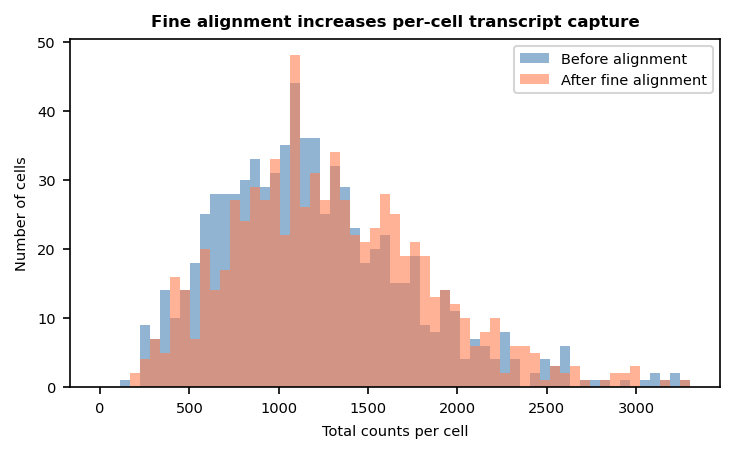

In [16]:
# Make cells from the raw (non-aligned) spots using the same NeuN boundaries
sample.omics['spots'].use_fine_alignment = False # turn off for comparison
adata_cells_raw = make_cells_from_masks(
    sample.omics['spots'], list(nuclei_rois.polygons.values()), min_obs=5)
sample.omics['spots'].use_fine_alignment = True  # re-enable for downstream steps

# Total counts per cell (sum across all genes) is the right metric for Visium:
# n_obs just counts bins in/out; total_counts reflects whether the bins that
# land inside are the dense, high-expression nuclear centres vs inter-nuclear gaps.
def _cell_total_counts(adata):
    X = adata.X
    return np.array(X.sum(axis=1)).flatten()

tc_raw  = _cell_total_counts(adata_cells_raw)
tc_corr = _cell_total_counts(adata_cells)

cap  = np.percentile(np.concatenate([tc_raw, tc_corr]), 99)
bins = np.linspace(0, cap, 60)

from platpy.plot_utils import PlotObject
plot_image_grid(
    [(
        PlotObject(tc_raw,  plot_type='histogram', bins=bins, color='steelblue',
                   alpha=0.6, label='Before alignment',
                   title='Fine alignment increases per-cell transcript capture',
                   xlabel='Total counts per cell', ylabel='Number of cells'),
        PlotObject(tc_corr, plot_type='histogram', bins=bins, color='coral',
                   alpha=0.6, label='After fine alignment'),
    )],
    width=5, font_size='small')

print(f'Before  median total counts = {np.median(tc_raw):.1f}')
print(f'After   median total counts = {np.median(tc_corr):.1f}')
print(f'Improvement: {(np.median(tc_corr)/np.median(tc_raw) - 1)*100:.1f}%')

# Field statistics
print(f'dy field  mean={fa.field_dy_um.mean():.2f}  std={fa.field_dy_um.std():.2f}  range=[{fa.field_dy_um.min():.1f}, {fa.field_dy_um.max():.1f}] \u00b5m')
print(f'dx field  mean={fa.field_dx_um.mean():.2f}  std={fa.field_dx_um.std():.2f}  range=[{fa.field_dx_um.min():.1f}, {fa.field_dx_um.max():.1f}] \u00b5m')
_disp_mag = np.sqrt(fa.field_dy_um**2 + fa.field_dx_um**2)
print(f'median_displacement_um = {np.median(_disp_mag):.2f} \u00b5m')
print(f'max_displacement_um    = {fa.max_displacement_um:.2f} \u00b5m')

### Step 5: Segment the NeuN-negative cells via DAPI residual segmentation

NeuN marks neurons specifically. Everything else (such as glia or endothelial cells) 
is still visible in DAPI. We can segment those residual nuclei by:

1. Running Cellpose on the DAPI channel in the same ROI (model already loaded)
2. Dilating the NeuN mask by a small border to cleanly exclude NeuN+ regions
3. Zeroing those regions from the DAPI result; what remains are the NeuN negative nuclei
4. Adding them to the AnnData and re-running UMAP on the combined set

channels deprecated in v4.0.1+. If data contain more than 3 channels, only the first 3 channels will be used


NeuN mask rescaled: (700, 225) -> (2800, 900)  (0.5 Ã‚Âµm/px)
DAPI residual Cellpose: 413 non-neuronal nuclei  |  shape: (2800, 900)
  Safety pass removed 115 cells overlapping NeuN zone
  Expanded by 5 px (2.5 um at 0.5 um/px)
  Spatial index: 1102 bins at 200 µm  |  2,170,414 spots
  Cells retained: 285  (from 298 boundaries, min_obs=5)
Non-neuronal cells with >=5 bins: 285


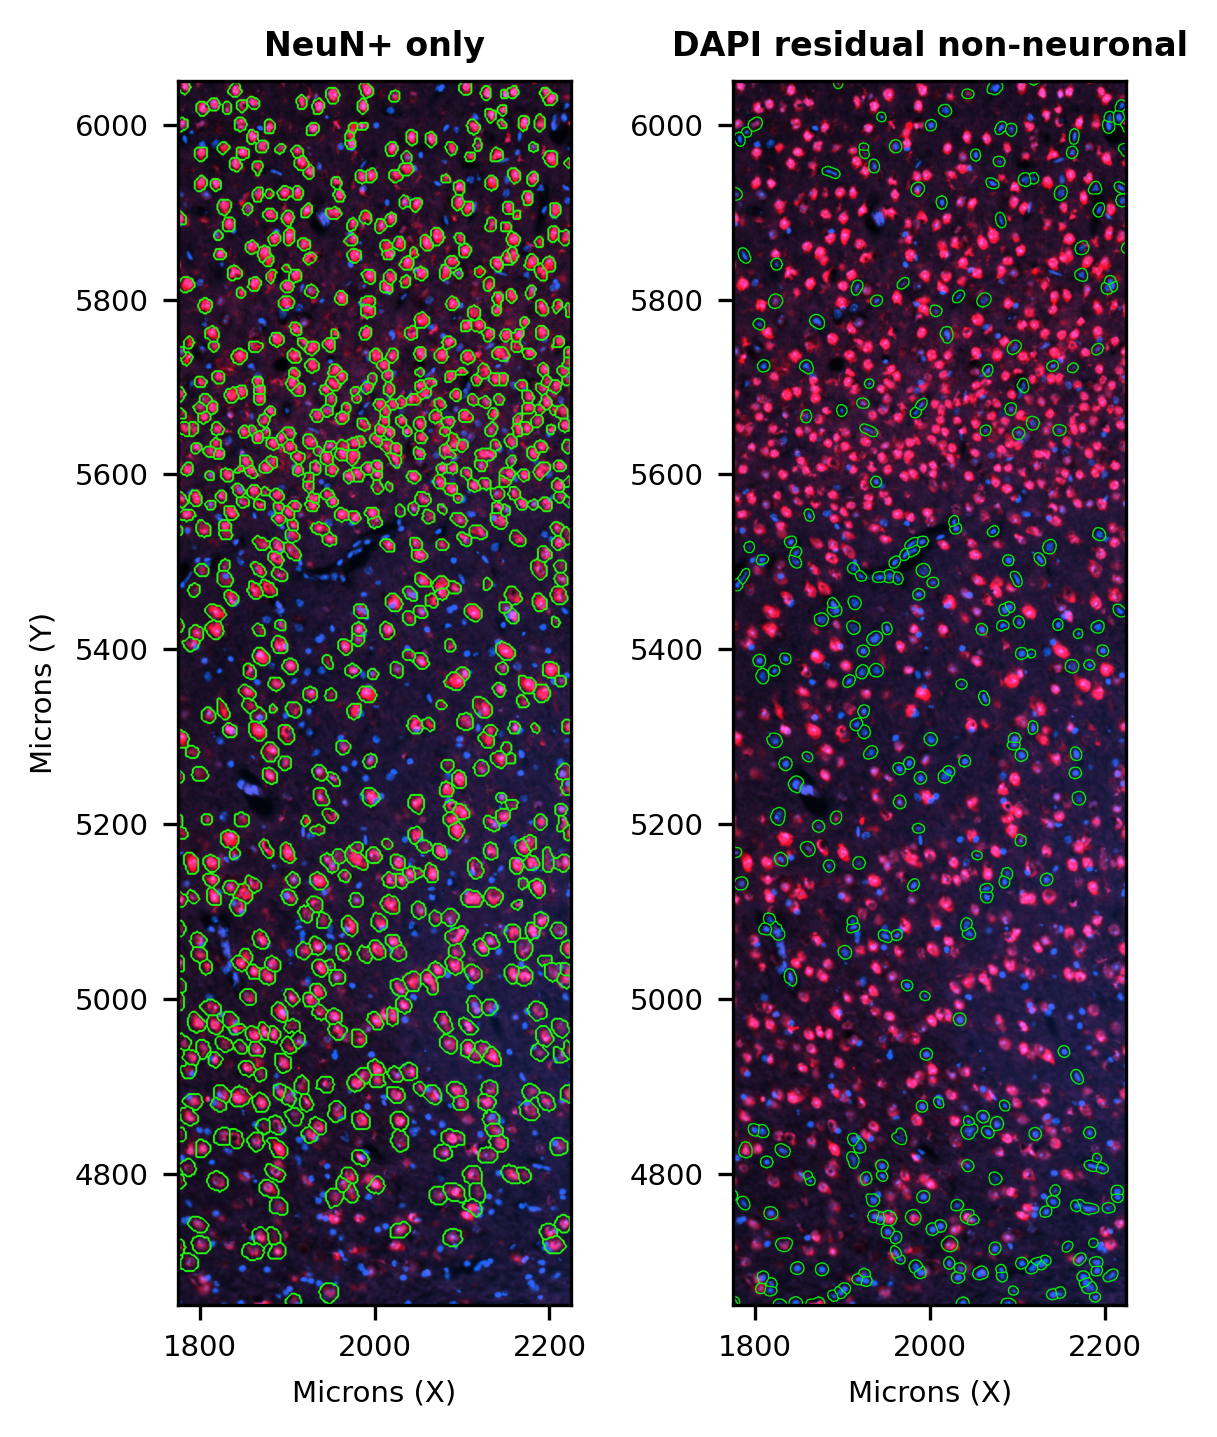

In [17]:
from scipy.ndimage import binary_dilation
from skimage.transform import resize as sk_resize

dapi_mpp = 0.5   # tune here Ã¢â‚¬â€ lower catches smaller non-neuronal nuclei

# Scale NeuN masks to match the DAPI render resolution
# (masks were generated at 2.0 mpp by the NeuN Cellpose step)
scale    = 2.0 / dapi_mpp
target_h = round(masks.shape[0] * scale)
target_w = round(masks.shape[1] * scale)
masks_scaled = sk_resize(masks, (target_h, target_w),
                          order=0, preserve_range=True, anti_aliasing=False).astype(bool)
print(f'NeuN mask rescaled: {masks.shape} -> {masks_scaled.shape}  ({dapi_mpp} µm/px)')

def _masked_dapi_cellpose(arr):
    bg = int(arr.min())              # burn to detector floor, not zero
    arr_masked = arr.copy()
    arr_masked[masks_scaled] = bg
    return model.eval(arr_masked, diameter=None, channels=[0, 0],
                      cellprob_threshold=-2.0)[0]

results_dapi = dp_ctx.process(
    sample.images['dapi'],
    fn=_masked_dapi_cellpose,
    downsample_mpp=dapi_mpp
)
_, masks_dapi = results_dapi[0]
del _masked_dapi_cellpose   # closure held a reference to masks_scaled; no longer needed

# We're done with Cellpose, so we can free up its memory allocations.
del model
if torch.backends.mps.is_available():
    torch.mps.empty_cache()
elif torch.cuda.is_available():
    torch.cuda.empty_cache()

print(f'DAPI residual Cellpose: {masks_dapi.max():,} non-neuronal nuclei  |  shape: {masks_dapi.shape}')

# Safety pass: dilate scaled NeuN mask to catch cells straddling the boundary
neun_dilated = binary_dilation(masks_scaled, iterations=2)
del masks_scaled   # consumed into neun_dilated; free the 900x2800 bool array
overlap_labels = np.unique(masks_dapi[neun_dilated])
overlap_labels = overlap_labels[overlap_labels > 0]
if len(overlap_labels):
    masks_dapi[np.isin(masks_dapi, overlap_labels)] = 0
    print(f'  Safety pass removed {len(overlap_labels)} cells overlapping NeuN zone')
del neun_dilated   # overlap check done; free the other 900x2800 bool array

# Expand non-neuronal masks to better capture full nuclear extent
# (non-neuronal cells are smaller than neurons; tune expand_px as needed)
from skimage.segmentation import expand_labels
expand_px  = 5
masks_dapi = expand_labels(masks_dapi, distance=expand_px)
print(f'  Expanded by {expand_px} px ({expand_px * dapi_mpp:.1f} um at {dapi_mpp} um/px)')

# -- Build non-neuronal cells AnnData ---
nonneu_rois  = DataPort.mask_to_roi_channel(masks_dapi, extent_ctx_um,
                                             name='nonneuronal', prefix='glia')
adata_nonneu = make_cells_from_masks(sample.omics['spots'], list(nonneu_rois.polygons.values()), min_obs=5)
print(f'Non-neuronal cells with >=5 bins: {adata_nonneu.n_obs:,}')

# -- Visualise ---
dapi_residual_rois = nonneu_rois.set_style(
    line_color='xkcd:bright green', line_width=2, fill=False)
all_seg_view = vp_ctx.clone()
all_seg_view.add_layer(dapi_residual_rois)
plot_image_grid(
    [seg_view.render(), all_seg_view.render()],
    titles=['NeuN+ only', 'DAPI residual non-neuronal'],
    width=4, font_size='small', dpi=300
);


### Step 6: UMAP of spatially-resolved NeuN+ neurons

Standard scanpy PCA -> UMAP -> Leiden on the per-cell AnnData from Step 5.
The payoff plot: clusters that emerge from transcript similarity should also be
spatially coherent neurons that cluster together transcriptionally live
together in the tissue.


Combined: 1,046 cells  (761 NeuN+  +  285 DAPI)
Low-count filter (20th pct, <515 counts): 209 cells removed, 837 retained
5 Leiden clusters
Top 10 marker genes per Leiden cluster:
   Cluster 0 Cluster 1 Cluster 2 Cluster 3 Cluster 4
1       Plp1      Pcp4     Pvalb      Bcan   Camk2n1
2       Sgk1     Basp1     Coro6    Atp1a2   Tmem145
3        Mag       Mbp     Cplx1     Aldoc    R3hdm1
4       Mobp    Col6a1    Atp1a3    Slc1a2    Snhg11
5       Apod     Efhd2    Atp1b1      Apoe    Arpp21
6       Car2      Dkk3      Peg3   mt-Atp8    Camk2a
7        Trf      Ighm    Snhg11    Grin2c      Nrgn
8     Cldn11       Vxn     Cend1     Htra1      Cux2
9     Sez6l2     Cplx2     Kcnc3    mt-Co3     Kalrn
10       Mal   Khdrbs3     Ndrg4    Slc1a3      Cux1


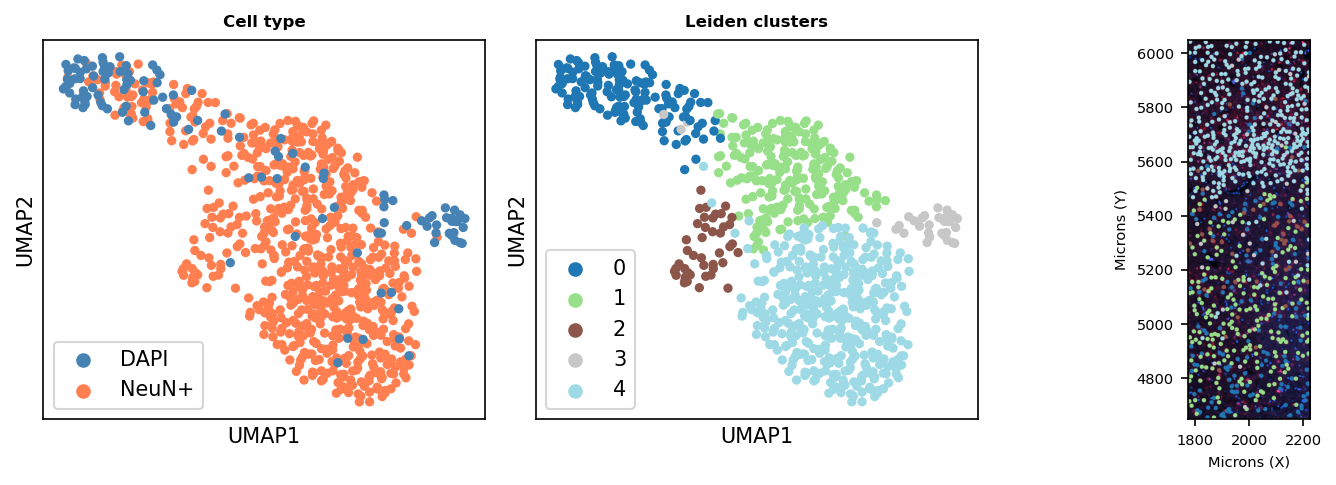

In [18]:
import scanpy as sc
import anndata as ad
import pandas as pd
import matplotlib.colors as mcolors
import tqdm as notebook_tqdm

########
##  This is a typical scanpy workflow for clustering and visualization of single cell data
########

# Tag cell types before merging 
adata_cells.obs['cell_type']  = 'NeuN+'
adata_nonneu.obs['cell_type'] = 'DAPI'

adata_combined = ad.concat([adata_cells, adata_nonneu], merge='same')
adata_combined.obs_names_make_unique()
adata_combined.obs['cell_type'] = adata_combined.obs['cell_type'].astype('category')
print(f'Combined: {adata_combined.n_obs:,} cells  '
      f'({adata_cells.n_obs:,} NeuN+  +  {adata_nonneu.n_obs:,} DAPI)')

# Low-count filter
min_count_pct  = 20   # drop bottom N% by total_counts to remove partial / noisy cells
min_counts     = np.percentile(adata_combined.obs['total_counts'], min_count_pct)
n_before       = adata_combined.n_obs
adata_combined = adata_combined[adata_combined.obs['total_counts'] >= min_counts].copy()
print(f'Low-count filter ({min_count_pct}th pct, <{min_counts:.0f} counts): '
      f'{n_before - adata_combined.n_obs} cells removed, {adata_combined.n_obs:,} retained')

# Scanpy pipeline on combined set
sc.pp.normalize_total(adata_combined, target_sum=1e4)
sc.pp.log1p(adata_combined)
sc.pp.highly_variable_genes(adata_combined, n_top_genes=2000)
sc.pp.pca(adata_combined, n_comps=30)
sc.pp.neighbors(adata_combined)
sc.tl.umap(adata_combined)
sc.tl.leiden(adata_combined, resolution=0.5, flavor='igraph', n_iterations=2)
print(f'{adata_combined.obs["leiden"].nunique()} Leiden clusters')

# Build a Leiden palette and store it in uns so that render_to_canvas and sc.pl.umap
# both use the exact same colors (scanpy only writes leiden_colors to uns on first plot).
leiden_cats = adata_combined.obs['leiden'].cat.categories.tolist()
rgba = plt.cm.tab20(np.linspace(0, 1, len(leiden_cats)))
leiden_palette = {cl: tuple(rgba[i]) for i, cl in enumerate(leiden_cats)}
adata_combined.uns['leiden_colors'] = [mcolors.to_hex(rgba[i]) for i in range(len(leiden_cats))]

from platpy.channels import CellChannel

cell_ch       = CellChannel(name='cells', data=adata_combined)
tissue_canvas = vp_ctx.render()
cells_img     = cell_ch.render_to_canvas(tissue_canvas, 'leiden',
                                          palette=leiden_palette,
                                          dot_radius_um=8.0, alpha=1.0)
vp_final      = vp_ctx.clone()
vp_final.add_layer(cells_img)

from platpy.plot_utils import PlotObject
plot_image_grid([
    PlotObject(adata_combined, plot_type='umap', color='cell_type', s=80,
               palette={'NeuN+': 'coral', 'DAPI': 'steelblue'},
               title='Cell type', legend_loc='lower left'),
    PlotObject(adata_combined, plot_type='umap', color='leiden', s=80,
               title='Leiden clusters', legend_loc='lower left'),
    vp_final.render(),
], width=10, font_size='small', dpi=150, uniform_size=True, titles=None);

# Top marker genes per cluster to identify what cell type they represent
sc.tl.rank_genes_groups(adata_combined, 'leiden', method='wilcoxon', n_genes=10)
marker_df = pd.DataFrame(adata_combined.uns['rank_genes_groups']['names'])
marker_df.index = pd.RangeIndex(1, len(marker_df) + 1)
marker_df.columns = [f'Cluster {c}' for c in marker_df.columns]
print('Top 10 marker genes per Leiden cluster:')
print(marker_df.to_string())

#### Investigating the fine details

The marker table above helps us interpret the UMAP and distribution plots.  

- Clusters 0 and 3 map to oligodendrocytes (Plp1) and astrocytes (Aldoc), respectively. 
- Cluster 1 is lower layer pyramidal neurons (e.g. Pcp4 = layer 5/6).
- Cluster 2 is cortical interneurons (Pvalb)
- Cluster 4 is upper layer cortical neurons (Camk2, Cux1, Cux2)

However, there does appear to be some misplaced assignments: API+ cells mixed in with presumptive neural cells, and NeuN+ cells mixed in with presumptive non-neural cells. Let's take a look at these populations to see if we can identify where this mismatch comes from.

First, let's take a look at the levels of DAPI and NeuN fluorescence in each cell type.

NeuN+  cells: 784   median NeuN intensity = 0.421
DAPI+  cells: 298   median NeuN intensity = 0.086


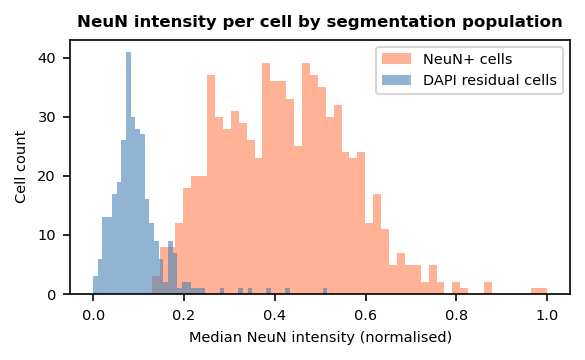

In [19]:
# Diagnostic: NeuN signal distribution across segmentation populations
# Reveals cross-contamination Ã¢â‚¬â€ oligos in NeuN+ gate, missed neurons in DAPI gate
from skimage.transform import resize as sk_resize

# Downsample DAPI masks (0.5 mpp) to match neun_norm resolution (2.0 mpp)
# (we sent lower resolution images to Cellpose for NeuN becasue it's easier to segment)
masks_dapi_lowres = sk_resize(masks_dapi, neun_norm.shape,
                              order=0, preserve_range=True, anti_aliasing=False).astype(int)

# Median NeuN intensity per cell in each population
neun_labels  = np.unique(masks)[1:]
dapi_labels  = np.unique(masks_dapi_lowres)[1:]

neun_medians = np.array([np.median(neun_norm[masks == lbl])             for lbl in neun_labels])
dapi_medians = np.array([np.median(neun_norm[masks_dapi_lowres == lbl]) for lbl in dapi_labels])

print(f'NeuN+  cells: {len(neun_medians):,}   median NeuN intensity = {np.median(neun_medians):.3f}')
print(f'DAPI+  cells: {len(dapi_medians):,}   median NeuN intensity = {np.median(dapi_medians):.3f}')

from platpy.plot_utils import PlotObject
plot_image_grid(
    [(
        PlotObject(neun_medians, plot_type='histogram', bins=50, color='coral',
                   alpha=0.6, label='NeuN+ cells',
                   title='NeuN intensity per cell by segmentation population',
                   xlabel='Median NeuN intensity (normalised)', ylabel='Cell count'),
        PlotObject(dapi_medians, plot_type='histogram', bins=50, color='steelblue',
                   alpha=0.6, label='DAPI residual cells'),
    )],
    width=4, font_size='small')

# Attach per-cell NeuN intensity to adata_combined for downstream use.
# obs names are sequential (not mask labels), so we convert centroids to pixels
# and sample whichever mask the centroid falls in.
min_x, _, min_y, _ = extent_ctx_um
neun_lut = dict(zip(neun_labels.tolist(), neun_medians.tolist()))
dapi_lut  = dict(zip(dapi_labels.tolist(), dapi_medians.tolist()))

xs = np.clip(((adata_combined.obs['x_micron'].values - min_x) / 2.0).round().astype(int), 0, neun_norm.shape[1] - 1)
ys = np.clip(((adata_combined.obs['y_micron'].values - min_y) / 2.0).round().astype(int), 0, neun_norm.shape[0] - 1)

lbl_n = masks[ys, xs]
lbl_d = masks_dapi_lowres[ys, xs]
adata_combined.obs['neun_intensity'] = [
    neun_lut[n] if n in neun_lut else (dapi_lut[d] if d in dapi_lut else float(neun_norm[y, x]))
    for n, d, y, x in zip(lbl_n, lbl_d, ys, xs)
]


Above, it appears that the NeuN intensities for the cells picked up by Cellpose as NeuN+ and NeuN-
overlap somewhat.  This might be part of our ambibuity, so let's exclude those cells.  

The result is better, but not perfect.  It's likely that some non-neural cells are closely associated 
with neurons, which complicates analysis.  Fine spatial alignment allows for further investigation
of this and other biological issues.

Rescued 6 DAPI Ã¢â€ â€™ NeuN+ cells (NeuN intensity > 0.25)
Ambiguous zone (NeuN 0.15Ã¢â‚¬â€œ0.25): 93 of 837 cells excluded (11.1%)


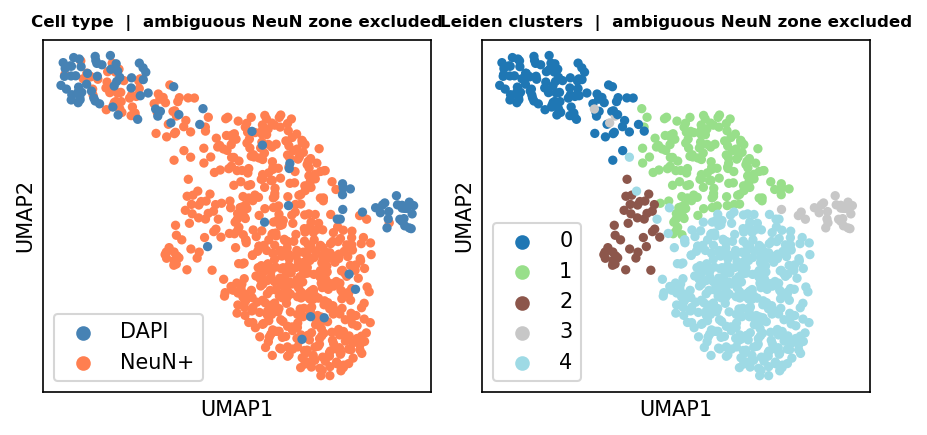

In [20]:
amb_lo, amb_hi = 0.15, 0.25

# Rescue DAPI+ cells with high NeuN signal Ã¢â‚¬â€ Cellpose was slightly grabby
# and caught some NeuN+ nuclei in the residual DAPI pass.
neun_rescue = (adata_combined.obs['cell_type'] == 'DAPI') & \
              (adata_combined.obs['neun_intensity'] > amb_hi)
n_rescued = int(neun_rescue.sum())
if n_rescued:
    adata_combined.obs.loc[neun_rescue, 'cell_type'] = 'NeuN+'
    print(f'Rescued {n_rescued} DAPI → NeuN+ cells (NeuN intensity > {amb_hi})')

# Exclude ambiguous zone (neither clearly NeuN+ nor clearly DAPI)
is_amb = ((adata_combined.obs['neun_intensity'] >= amb_lo) &
          (adata_combined.obs['neun_intensity'] <= amb_hi)).values
print(f'Ambiguous zone (NeuN {amb_lo}–{amb_hi}): {is_amb.sum():,} of {len(is_amb):,} cells excluded '
      f'({is_amb.mean()*100:.1f}%)')

adata_unamb = adata_combined[~is_amb].copy()

plot_image_grid([
    PlotObject(adata_unamb, plot_type='umap', color='cell_type', s=80,
               palette={'NeuN+': 'coral', 'DAPI': 'steelblue'},
               title='Cell type  |  ambiguous NeuN zone excluded', legend_loc='lower left'),
    PlotObject(adata_unamb, plot_type='umap', color='leiden', s=80,
               title='Leiden clusters  |  ambiguous NeuN zone excluded', legend_loc='lower left'),
], width=6, font_size='small');

#### Fine alignment closes the gap between imaging and biology
In this example, you may have noticed a few key things:

- **Sub-pixel registration is done algorithmically, not by hand.** Small offsets between imaging channels accumulate from optical differences, tissue handling, and scan geometry. Platpy computes a displacement field from the data itself and stores the correction transparently Ã¢â‚¬â€ no manual alignment, no external tools.
- **The corrected coordinates are always available without losing the originals.** Fine-aligned coordinates live alongside the raw coordinates in the same data structure. The ViewPort and DataPort use the corrected positions automatically when they're available, but you can switch back to raw coordinates at any time.
- **This makes simultaneous use of imaging and transcript data feasible.** Using the spatial tools provided by platpy, immunofluorescent and transcript-level channels can be fine-aligned to a sufficient degree to allow both data layers to be used simultaneously for analysis.

There are still technical limitations and biological realities that make this type of multi-modal analysis challenging: spatial datasets include parts of cells, cells of very different sizes and morphologies, and cells whose nuclei are positioned very close to each other. Each makes algorithmic segmentation challenging, and in some cases it may not be possible to physically identify which transcripts belong to different cells. Nevertheless, platpy provides the spatial infrastructure to make it possible to attack this problem without spending hours writing code to manually align layers, and provides an underlying data structure that doesn't require loading multiple multi-gigabyte data and image sets in memory at one time to perform tasks such as fine layer alignment.